# Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load Dataset

In [2]:
df = pd.read_csv('Students Performance Dataset.csv')
print(df)

    Student ID Student Name  Python  Java  Linux  AI  SQL  Total Attendance
0         1001         Abhi      41    53     33  95   45    267        97%
1         1002        Abhay      37    60     78  71   67    313        98%
2         1003      Bhaskar      34    65     72  57   38    266        98%
3         1004         Bala      61    80     61  78   51    331        98%
4         1005        Bhati      71    59     65  51   59    305        98%
5         1006     Chandran      77    47     90  54   83    351        98%
6         1007       Chawla      97    92     82  72   75    418        98%
7         1008         Dora      93    42     86  51   67    339        98%
8         1009     Francies      39    90     65  35   46    275       100%
9         1010       Gerage      58    36     88  41   61    284        96%
10        1011        Gopal      55    48     77  37   96    313        99%
11        1012     JaiKanth      48    60     54  84   52    298        94%
12        10

In [3]:
df.head()

,Student ID,Student Name,Python,Java,Linux,AI,SQL,Total,Attendance
0,1001,Abhi,41,53,33,95,45,267,97%
1,1002,Abhay,37,60,78,71,67,313,98%
2,1003,Bhaskar,34,65,72,57,38,266,98%
3,1004,Bala,61,80,61,78,51,331,98%
4,1005,Bhati,71,59,65,51,59,305,98%


In [4]:
df.tail()

,Student ID,Student Name,Python,Java,Linux,AI,SQL,Total,Attendance
13,1014,Kandan,64,92,85,37,61,339,96%
14,1015,Kala,44,66,90,84,93,377,98%
15,1016,Kamal,77,75,63,39,52,306,100%
16,1017,Lal,94,69,71,96,91,421,100%
17,1018,Lalli,47,72,42,84,60,305,100%


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Student ID    18 non-null     int64 
 1   Student Name  18 non-null     object
 2   Python        18 non-null     int64 
 3   Java          18 non-null     int64 
 4   Linux         18 non-null     int64 
 5   AI            18 non-null     int64 
 6   SQL           18 non-null     int64 
 7   Total         18 non-null     int64 
 8   Attendance    18 non-null     object
dtypes: int64(7), object(2)
memory usage: 1.4+ KB


In [6]:
df.describe()

,Student ID,Python,Java,Linux,AI,SQL,Total
count,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000
mean,1009.500000,63.111111,65.666667,69.444444,62.555556,66.388889,327.166667
std,5.338539,22.071778,16.803361,17.037061,20.881239,18.824699,47.234397
min,1001.000000,34.000000,36.000000,33.000000,35.000000,38.000000,266.000000
25%,1005.250000,44.750000,54.500000,61.500000,43.500000,52.000000,299.750000
50%,1009.500000,59.500000,65.500000,71.500000,58.500000,61.000000,313.000000
75%,1013.750000,77.000000,75.750000,84.250000,82.500000,81.000000,348.000000
max,1018.000000,99.000000,92.000000,90.000000,96.000000,98.000000,421.000000


In [7]:
df.isnull().sum()

Student ID      0
Student Name    0
Python          0
Java            0
Linux           0
AI              0
SQL             0
Total           0
Attendance      0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [21]:
import pandas as pd

df = pd.read_csv('Students Performance Dataset.csv')
df.columns = df.columns.str.strip()

SUBJECTS = ["Python", "Java", "Linux", "AI", "SQL"]
DEPARTMENTS = ["Computer Science", "Information Technology", "AI and Data Science"]

df["Attendance"] = pd.to_numeric(
    df["Attendance"].astype(str).str.rstrip("%"), errors="coerce"
)

df["Department"] = [DEPARTMENTS[i % len(DEPARTMENTS)] for i in range(len(df))]

df = df.rename(columns={"Total": "Source_Total"})
df = df[["Student ID", "Student Name", "Department"] + SUBJECTS + ["Attendance", "Source_Total"]]

df.head()


,Student ID,Student Name,Department,Python,Java,Linux,AI,SQL,Attendance,Source_Total
0,1001,Abhi,Computer Science,41,53,33,95,45,97,267
1,1002,Abhay,Information Technology,37,60,78,71,67,98,313
2,1003,Bhaskar,AI and Data Science,34,65,72,57,38,98,266
3,1004,Bala,Computer Science,61,80,61,78,51,98,331
4,1005,Bhati,Information Technology,71,59,65,51,59,98,305


## Rules Used in the Student Performance System
### Grading Rule ( based on the student's ** average marks** ; every subject is out of 100)
| Average marks | Grade |
|---|---|
| 90 and above | **A+** |
| 80 - 89.99 | **A** |
| 70 - 79.99 | **B** |
| 60 - 69.99 | **C** |
| 50 - 59.99 | **D** |
| Below 50 | **F** |

### Pass / Fail rule
A student **passes** only if **both** conditions hold:
1. Marks ≥ **40** in **every** subject, and
2. Attendance ≥ **75%**.

Otherwise the student **fails**. (Change the constants below to use a different rule.)


In [23]:
MAX_MARKS_PER_SUBJECT = 100
PASS_MARK = 40
MIN_ATTENDANCE = 75
TOP_N = 5 
GRADE_BOUNDARIES = [(90,"A+"),(80,"A"),(70,"B"),(60,"C"),(50,"D")]
LOWEST_GRADE = "F"

# Reusable Functions

In [35]:
import numpy as np

SUBJECTS = ["Python", "Java", "Linux", "AI", "SQL"]
PASS_MARK = 40
MIN_ATTENDANCE = 75
GRADE_BOUNDARIES = [(90, "A+"), (80, "A"), (70, "B"), (60, "C"), (50, "D")]
LOWEST_GRADE = "F"

def calculate_total(marks):
    return np.sum(marks, axis=1)

def calculate_average(marks):
    return np.round(np.mean(marks, axis=1), 2)

def assign_grade(average):
    for lower_bound, grade in GRADE_BOUNDARIES:
        if average >= lower_bound:
            return grade
    return LOWEST_GRADE

def check_pass_fail(marks_row, attendance):
    passed_all_subjects = np.all(marks_row >= PASS_MARK)
    if passed_all_subjects and attendance >= MIN_ATTENDANCE:
        return "Pass"
    return "Fail"

def failed_subjects(marks_row, subjects=SUBJECTS):
    return [subj for subj, m in zip(subjects, marks_row) if m < PASS_MARK]

def subject_statistics(column):
    column = np.asarray(column)
    return {
        "Average": round(float(np.mean(column)), 2),
        "Median": float(np.median(column)),
        "Highest": int(np.max(column)),
        "Lowest": int(np.min(column)),
        "Std Deviation": round(float(np.std(column)), 2),
        "Pass %": round(float(np.mean(column >= PASS_MARK) * 100), 2),
    }

## Student-wise Results

Total, average, grade and pass/fail for each student.

In [39]:
MAX_MARKS_PER_SUBJECT = 100   

df = df.reset_index(drop=True)   

marks = df[SUBJECTS].to_numpy()

df["Total"] = calculate_total(marks)
df["Average"] = calculate_average(marks)
df["Percentage"] = np.round(
    df["Total"] / (len(SUBJECTS) * MAX_MARKS_PER_SUBJECT) * 100, 2
)

grades, statuses, fails = [], [], []
for idx in range(len(df)):
    grades.append(assign_grade(df.loc[idx, "Average"]))
    statuses.append(check_pass_fail(marks[idx], df.loc[idx, "Attendance"]))
    fails.append(",".join(failed_subjects(marks[idx])) or "-")

df["Grade"] = grades
df["Status"] = statuses
df["Failed Subjects"] = fails

mismatches = int((df["Total"] != df["Source_Total"]).sum())
print(f"Rows where calculated total != file total: {mismatches}")

df[["Student ID", "Student Name", "Department", "Total", "Average",
    "Grade", "Status", "Failed Subjects"]]

Rows where calculated total != file total: 0


,Student ID,Student Name,Department,Total,Average,Grade,Status,Failed Subjects
0,1001,Abhi,Computer Science,267,53.4,D,Fail,Linux
1,1002,Abhay,Information Technology,313,62.6,C,Fail,Python
2,1003,Bhaskar,AI and Data Science,266,53.2,D,Fail,"Python,SQL"
3,1004,Bala,Computer Science,331,66.2,C,Pass,-
4,1005,Bhati,Information Technology,305,61.0,C,Pass,-
5,1006,Chandran,AI and Data Science,351,70.2,B,Pass,-
6,1007,Chawla,Computer Science,418,83.6,A,Pass,-
7,1008,Dora,Information Technology,339,67.8,C,Pass,-
8,1009,Francies,AI and Data Science,275,55.0,D,Fail,"Python,AI"
9,1010,Gerage,Computer Science,284,56.8,D,Fail,Java


## Grade distribution and pass/fail summary

In [88]:
from IPython.display import display

subjects = ["Python", "SQL", "Java", "Linux", "AI"]

# Create the missing "Failed Subjects" column (subjects scored below 50)
df["Failed Subjects"] = df[subjects].apply(
    lambda row: ", ".join(row.index[row < 50]) or "None", axis=1
)

# Grade distribution
grade_order = ["A+", "A", "B", "C", "D", "F"]
grade_counts = df["Grade"].value_counts().reindex(grade_order, fill_value=0)
print("Grade distribution:")
print(grade_counts.to_string())

# Pass / fail summary
n_students = len(df)
n_pass = int((df["Result"] == "Pass").sum())
n_fail = n_students - n_pass
print(f"\nPassed: {n_pass}  |  Failed: {n_fail}  |  Pass rate: {n_pass / n_students * 100:.1f}%")

# Failed students
print("\nStudents who failed:")
failed = df.loc[df["Result"] == "Fail", ["Student_ID", "Name", "Average", "Grade", "Failed Subjects"]]

if failed.empty:
    print("No students failed.")
else:
    display(failed.reset_index(drop=True))

Grade distribution:
Grade
A+    0
A     2
B     3
C     8
D     5
F     0

Passed: 13  |  Failed: 5  |  Pass rate: 72.2%

Students who failed:


,Student_ID,Name,Average,Grade,Failed Subjects
0,1014,JaiKanth,59.6,D,Python
1,1015,Gerage,56.8,D,"Java, AI"
2,1016,Francies,55.0,D,"Python, SQL, AI"
3,1017,Abhi,53.4,D,"Python, SQL, Linux"
4,1018,Bhaskar,53.2,D,"Python, SQL"


## Overall Performance: Highest, Lowest & Average

In [40]:
totals = df["Total"].to_numpy()
best_i = int(np.argmax(totals))
worst_i = int(np.argmin(totals))

print("=" * 55)
print("OVERALL CLASS PERFORMANCE")
print("=" * 55)
print(f"Highest total : {totals[best_i]} -> {df.loc[best_i, 'Student Name']}"
      f"Avg : {df.loc[best_i,'Average']},Grade {df.loc[best_i, 'Grade']}")
print(f"Lowest total : {totals[worst_i]} -> {df.loc[worst_i, 'Student Name']}" 
      f"Avg : {df.loc[worst_i,'Average']},Grade {df.loc[worst_i, 'Grade']}")
print(f"Class average total : {np.mean(totals):2f}")
print(f"Class average marks : {np.mean(df['Average']):.2f}")
print(f"Median total        : {np.median(totals):2f}")
print(f"Standard deviation : {np.std(totals):.2f}")
print(f"Average attendance : {np.mean(df['Attendance']):.2f}%")



OVERALL CLASS PERFORMANCE
Highest total : 421 -> LalAvg : 84.2,Grade A
Lowest total : 266 -> BhaskarAvg : 53.2,Grade D
Class average total : 327.166667
Class average marks : 65.43
Median total        : 313.000000
Standard deviation : 45.90
Average attendance : 98.00%


In [46]:
subjects_rows = {}
for subject in SUBJECTS:
    subjects_rows[subject] = subject_statistics(df[subject].to_numpy())
subject_analysis = pd.DataFrame(subjects_rows).T
toppers, weakest = [],[]
for subject in SUBJECTS:
    col = df[subject].to_numpy()
    toppers.append(f"{df.loc[np.argmax(col), 'Student Name']} ({col.max()}")
    weakest.append(f"{df.loc[np.argmax(col), 'Student Name']} ({col.min()}")
subject_analysis["Topper"] = toppers
subject_analysis["Lowest Scorer"] = weakest
subject_analysis

,Average,Median,Highest,Lowest,Std Deviation,Pass %,Topper,Lowest Scorer
Python,63.11,59.5,99.0,34.0,21.45,83.33,Karthi (99,Karthi (34
Java,65.67,65.5,92.0,36.0,16.33,94.44,Chawla (92,Chawla (36
Linux,69.44,71.5,90.0,33.0,16.56,94.44,Chandran (90,Chandran (33
AI,62.56,58.5,96.0,35.0,20.29,77.78,Lal (96,Lal (35
SQL,66.39,61.0,98.0,38.0,18.29,94.44,Karthi (98,Karthi (38


In [48]:
strongest = subject_analysis["Average"].idxmax()
weakest_subj = subject_analysis["Average"].idxmin()
hardest_pass = subject_analysis["Pass %"].idxmin()
print(f"Strongest subject (highest class average): {strongest} ({subject_analysis.loc[strongest, 'Average']})")
print(f"Weakest subject (lowest class average) :   {weakest_subj} ({subject_analysis.loc[weakest_subj, 'Average']})")  
print(f"Subject with lowest pass %              : {hardest_pass} ({subject_analysis.loc[hardest_pass, 'Pass %' ]}%)")    

Strongest subject (highest class average): Linux (69.44)
Weakest subject (lowest class average) :   AI (62.56)
Subject with lowest pass %              : AI (77.78%)


# Top-performing Students

In [50]:
df["Rank"] = df["Total"].rank(method="min", ascending=False).astype(int)
top_students = (df.sort_values(["Total","Attendance"], ascending=False)
                .head(TOP_N)[["Rank","Student ID","Student Name","Department",
                              "Total","Average","Grade","Attendance"]]
                .reset_index(drop=True))
print(f"Top {TOP_N} students")
top_students

Top 5 students


,Rank,Student ID,Student Name,Department,Total,Average,Grade,Attendance
0,1,1017,Lal,Information Technology,421,84.2,A,100
1,2,1007,Chawla,Computer Science,418,83.6,A,98
2,3,1013,Karthi,Computer Science,381,76.2,B,98
3,4,1015,Kala,AI and Data Science,377,75.4,B,98
4,5,1006,Chandran,AI and Data Science,351,70.2,B,98


In [51]:
print("A+ students:", df.loc[df["Grade"] == "A+", "Student Name"].tolist() or "None")
print("\nTop Student per department:")
for dept in DEPARTMENTS:
    sub = df[df["Department"] ==dept]
    best = sub.loc[sub["Total"].idxmax()]
    print(f" {dept:<24} -> {best['Student Name']} (Total {best['Total']}, Avg {best['Average']})")


A+ students: None

Top Student per department:
 Computer Science         -> Chawla (Total 418, Avg 83.6)
 Information Technology   -> Lal (Total 421, Avg 84.2)
 AI and Data Science      -> Kala (Total 377, Avg 75.4)


# Department-Wise Summary

In [53]:
dept_summary = (df.groupby("Department").agg(Students=("Student ID","count"),
                                             Avg_Marks=("Average", "mean"),
                                             Highest_Total=("Total","max"),
                                             Lowest_Total=("Total","min"),
                                             Avg_Attendance=("Attendance","mean"),
                                             Passed=("Status", lambda s: (s == "Pass").sum())).round(2))
dept_summary["Pass %"] = np.round(dept_summary["Passed"] / dept_summary["Students"] * 100 ,2)
dept_summary

,Students,Avg_Marks,Highest_Total,Lowest_Total,Avg_Attendance,Passed,Pass %
Department,,,,,,,
AI and Data Science,6,62.40,377,266,98.00,4,66.67
Computer Science,6,66.23,418,267,97.83,3,50.00
Information Technology,6,67.67,421,305,98.17,3,50.00


# Visualisations

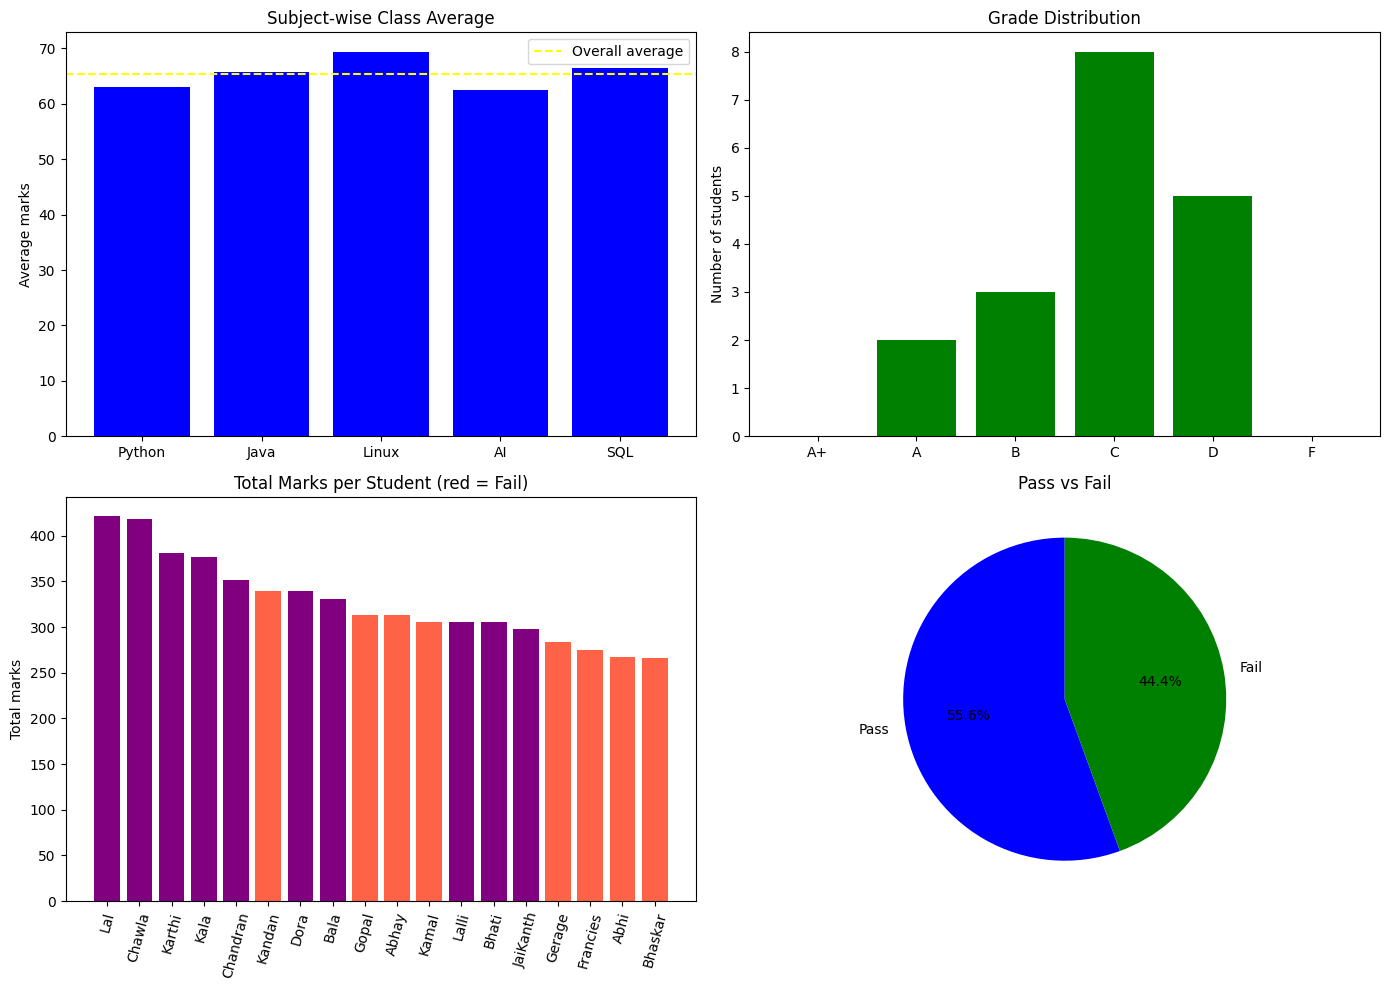

In [60]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Subject-wise class average
axes[0, 0].bar(subject_analysis.index, subject_analysis["Average"], color="blue")
axes[0, 0].axhline(df["Average"].mean(), color="yellow", linestyle="--", label="Overall average")
axes[0, 0].set_title("Subject-wise Class Average")
axes[0, 0].set_ylabel("Average marks")
axes[0, 0].legend()

# 2) Grade distribution
grade_order = ["A+", "A", "B", "C", "D", "F"]
grade_counts = df["Grade"].value_counts().reindex(grade_order, fill_value=0)
axes[0, 1].bar(grade_counts.index, grade_counts.values, color="green")
axes[0, 1].set_title("Grade Distribution")
axes[0, 1].set_ylabel("Number of students")

# 3) Total marks per student
order = df.sort_values("Total", ascending=False)
colors = ["tomato" if s == "Fail" else "purple" for s in order["Status"]]
axes[1, 0].bar(order["Student Name"], order["Total"], color=colors)
axes[1, 0].set_title("Total Marks per Student (red = Fail)")
axes[1, 0].tick_params(axis="x", rotation=75)
axes[1, 0].set_ylabel("Total marks")

# 4) Pass vs Fail
n_pass = int((df["Status"] == "Pass").sum())
n_fail = int((df["Status"] == "Fail").sum())
axes[1, 1].pie([n_pass, n_fail], labels=["Pass", "Fail"], autopct="%1.1f%%",
               colors=["blue", "green"], startangle=90)
axes[1, 1].set_title("Pass vs Fail")

plt.tight_layout()
plt.show()

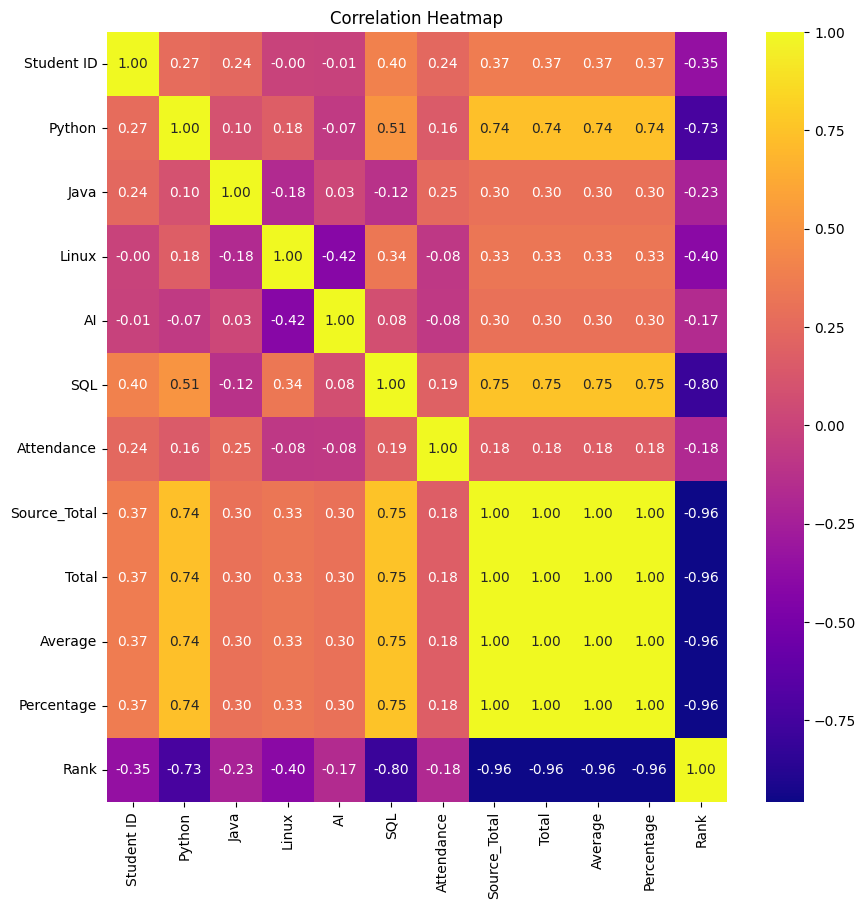

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
plt.figure (figsize=(10,10))
correlation = df.corr(numeric_only=True)
sns.heatmap (
      correlation,
      annot=True,
      cmap='plasma',
      fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

# Data Analysis Questions and Answers

# Which student has the highest average?

In [70]:
students = df.groupby("Student Name")["Total"].mean().idxmax()
print("Name of the Student with Highest Score", students)

Name of the Student with Highest Score Lal


# Which subject has the best average?

In [71]:
best_subject = subject_analysis["Average"].idxmax()
best_average =subject_analysis["Average"].max()
print(f"Best subject: {best_subject} (average {best_average})")

Best subject: Linux (average 69.44)


# How many students passed?

In [75]:
passed = (df["Status"] == "Pass").sum()
print("Number of Students Passed:",passed)

Number of Students Passed: 10


# What is the overall class average?

In [78]:
class_Total = df["Total"].mean()
print("Overall class average", class_Total)

Overall class average 327.1666666666667


In [64]:
final_report = df.drop(columns=["Source_Total"]).sort_values("Rank").reset_index(drop=True)
final_report.to_csv("Student_Performance_Report.csv", index=False)
print("Saved: Student_Performance_Report.csv")
final_report

Saved: Student_Performance_Report.csv


,Student ID,Student Name,Department,Python,Java,Linux,AI,SQL,Attendance,Total,Average,Percentage,Grade,Status,Failed Subjects,Rank
0,1017,Lal,Information Technology,94,69,71,96,91,100,421,84.2,84.2,A,Pass,-,1
1,1007,Chawla,Computer Science,97,92,82,72,75,98,418,83.6,83.6,A,Pass,-,2
2,1013,Karthi,Computer Science,99,76,48,60,98,98,381,76.2,76.2,B,Pass,-,3
3,1015,Kala,AI and Data Science,44,66,90,84,93,98,377,75.4,75.4,B,Pass,-,4
4,1006,Chandran,AI and Data Science,77,47,90,54,83,98,351,70.2,70.2,B,Pass,-,5
5,1008,Dora,Information Technology,93,42,86,51,67,98,339,67.8,67.8,C,Pass,-,6
6,1014,Kandan,Information Technology,64,92,85,37,61,96,339,67.8,67.8,C,Fail,AI,6
7,1004,Bala,Computer Science,61,80,61,78,51,98,331,66.2,66.2,C,Pass,-,8
8,1011,Gopal,Information Technology,55,48,77,37,96,99,313,62.6,62.6,C,Fail,AI,9
9,1002,Abhay,Information Technology,37,60,78,71,67,98,313,62.6,62.6,C,Fail,Python,9


# Final Output

In [86]:
import pandas as pd
import numpy as np
from IPython.display import display

# Student data
data = {
    "Student_ID": [
        1001, 1002, 1003, 1004, 1005, 1006,
        1007, 1008, 1009, 1010, 1011, 1012,
        1013, 1014, 1015, 1016, 1017, 1018
    ],

    "Name": [
        "Lal", "Chawla", "Karthi", "Kala", "Chandran",
        "Dora", "Kandan", "Bala", "Gopal", "Abhay",
        "Kamal", "Bhati", "Lalli", "JaiKanth", "Gerage",
        "Francies", "Abhi", "Bhaskar"
    ],

    "Department": [
        "Information Technology", "Computer Science", "Computer Science",
        "AI and Data Science", "AI and Data Science", "Information Technology",
        "Information Technology", "Computer Science", "Information Technology",
        "Information Technology", "Computer Science", "Information Technology",
        "AI and Data Science", "AI and Data Science", "Computer Science",
        "AI and Data Science", "Computer Science", "AI and Data Science"
    ],

    "Python": [94, 97, 99, 44, 77, 93, 64, 61, 55, 37, 77, 71, 47, 48, 58, 39, 41, 34],
    "SQL": [91, 75, 98, 93, 83, 67, 61, 51, 96, 67, 52, 59, 60, 52, 61, 46, 45, 38],
    "Java": [69, 92, 76, 66, 47, 42, 92, 80, 48, 60, 75, 59, 72, 60, 36, 90, 53, 65],
    "Linux": [71, 82, 48, 90, 90, 86, 85, 61, 77, 78, 63, 65, 42, 54, 88, 65, 33, 72],
    "AI": [96, 72, 60, 84, 54, 51, 37, 78, 37, 71, 39, 51, 84, 84, 41, 35, 95, 57],
    "Attendance": [100, 98, 98, 98, 98, 98, 96, 98, 99, 98, 100, 98, 100, 94, 96, 100, 97, 98]
}

# Create DataFrame
df = pd.DataFrame(data)

print("=" * 50)
print("STUDENT PERFORMANCE ANALYTICS SYSTEM")
print("=" * 50)

print("\n========== STUDENT DATA ==========")
print(df.to_string(index=False))

# Subject columns
subjects = ["Python", "SQL", "Java", "Linux", "AI"]

# Calculate total and average using NumPy
df["Total"] = np.sum(df[subjects].to_numpy(), axis=1)
df["Average"] = np.mean(df[subjects].to_numpy(), axis=1).round(2)

# Grade function
def grade(avg):
    if avg >= 90:
        return "A+"
    elif avg >= 80:
        return "A"
    elif avg >= 70:
        return "B"
    elif avg >= 60:
        return "C"
    else:
        return "D"

df["Grade"] = df["Average"].apply(grade)

# Pass / Fail function
def check_result(avg):
    return "Pass" if avg >= 60 else "Fail"

df["Result"] = df["Average"].apply(check_result)

# Display student performance
performance = df[
    ["Student_ID", "Name", "Department",
     "Total", "Average", "Grade", "Attendance", "Result"]
]

print("\n========== STUDENT PERFORMANCE ==========")
print(performance.to_string(index=False))

# Highest, lowest and overall average
print("\n========== OVERALL ANALYSIS ==========")
print("Highest Total Marks:", df["Total"].max())
print("Lowest Total Marks:", df["Total"].min())
print("Overall Average Marks:", round(df["Average"].mean(), 2))

# Top 5 students
print("\n========== TOP 5 STUDENTS ==========")
top_5 = df.nlargest(5, "Total")
print(top_5[["Student_ID", "Name", "Total", "Average", "Grade"]].to_string(index=False))

# Subject-wise average
print("\n========== SUBJECT-WISE AVERAGE ==========")
for subject in subjects:
    print(subject, ":", round(df[subject].mean(), 2))

# Pass and fail count
print("\n========== PASS / FAIL SUMMARY ==========")
print("Pass Students:", (df["Result"] == "Pass").sum())
print("Fail Students:", (df["Result"] == "Fail").sum())

# ---------- FAILED STUDENTS ----------
print("\n========== FAILED STUDENTS ==========")
failed_students = df[df["Result"] == "Fail"]

if failed_students.empty:
    print("No students failed.")
else:
    display(
        failed_students[
            ["Student_ID", "Name", "Department", "Total", "Average", "Grade", "Attendance", "Result"]
        ].reset_index(drop=True)
    )

STUDENT PERFORMANCE ANALYTICS SYSTEM

========== STUDENT DATA ==========
 Student_ID     Name             Department  Python  SQL  Java  Linux  AI  Attendance
       1001      Lal Information Technology      94   91    69     71  96         100
       1002   Chawla       Computer Science      97   75    92     82  72          98
       1003   Karthi       Computer Science      99   98    76     48  60          98
       1004     Kala    AI and Data Science      44   93    66     90  84          98
       1005 Chandran    AI and Data Science      77   83    47     90  54          98
       1006     Dora Information Technology      93   67    42     86  51          98
       1007   Kandan Information Technology      64   61    92     85  37          96
       1008     Bala       Computer Science      61   51    80     61  78          98
       1009    Gopal Information Technology      55   96    48     77  37          99
       1010    Abhay Information Technology      37   67    60     

,Student_ID,Name,Department,Total,Average,Grade,Attendance,Result
0,1014,JaiKanth,AI and Data Science,298,59.6,D,94,Fail
1,1015,Gerage,Computer Science,284,56.8,D,96,Fail
2,1016,Francies,AI and Data Science,275,55.0,D,100,Fail
3,1017,Abhi,Computer Science,267,53.4,D,97,Fail
4,1018,Bhaskar,AI and Data Science,266,53.2,D,98,Fail
